In [1]:
import pandas as pd

# Load the raw retail sales dataset
df = pd.read_csv("data/retail_store_sales.csv")

# Display the first five rows
df.head()

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,NaN
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False


In [2]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Examine column names, data types, and non-null counts
df.info()

Dataset shape: (12575, 11)
<class 'pandas.DataFrame'>
RangeIndex: 12575 entries, 0 to 12574
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    12575 non-null  str    
 1   Customer ID       12575 non-null  str    
 2   Category          12575 non-null  str    
 3   Item              11362 non-null  str    
 4   Price Per Unit    11966 non-null  float64
 5   Quantity          11971 non-null  float64
 6   Total Spent       11971 non-null  float64
 7   Payment Method    12575 non-null  str    
 8   Location          12575 non-null  str    
 9   Transaction Date  12575 non-null  str    
 10  Discount Applied  8376 non-null   object 
dtypes: float64(3), object(1), str(7)
memory usage: 1.1+ MB


In [3]:
# Count missing values in each column
missing_count = df.isnull().sum()

# Calculate percentage of missing values
missing_percentage = (missing_count / len(df)) * 100

# Create a data quality summary
missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage": missing_percentage.round(2)
})

missing_summary

,Missing Values,Missing Percentage
Transaction ID,0,0.00
Customer ID,0,0.00
Category,0,0.00
Item,1213,9.65
Price Per Unit,609,4.84
Quantity,604,4.80
Total Spent,604,4.80
Payment Method,0,0.00
Location,0,0.00
Transaction Date,0,0.00


In [4]:
pd.crosstab(
    df["Payment Method"],
    df["Discount Applied"].isna(),
    normalize="index"
).round(3) * 100

Discount Applied,False,True
Payment Method,,
Cash,65.8,34.2
Credit Card,66.9,33.1
Digital Wallet,67.2,32.8


In [5]:
# Investigate missing discount values by transaction location
pd.crosstab(
    df["Location"],
    df["Discount Applied"].isna(),
    normalize="index"
).round(3) * 100

Discount Applied,False,True
Location,,
In-store,66.3,33.7
Online,66.9,33.1


In [6]:
# Calculate missing discount percentage by product category
category_missing = (
    df.groupby("Category")["Discount Applied"]
    .apply(lambda x: x.isna().mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

category_missing

Category
Furniture                             35.83
Beverages                             35.16
Patisserie                            34.10
Electric household essentials         34.00
Food                                  33.56
Butchers                              32.59
Milk Products                         31.25
Computers and electric accessories    30.62
Name: Discount Applied, dtype: float64

In [7]:
# Check for completely duplicated rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

# Check for repeated transaction IDs
duplicate_ids = df["Transaction ID"].duplicated().sum()

print("Repeated Transaction IDs:", duplicate_ids)

Number of duplicate rows: 0
Repeated Transaction IDs: 0


In [8]:
# Select transactions with complete sales information
sales_check = df.dropna(
    subset=["Price Per Unit", "Quantity", "Total Spent"]
).copy()

# Calculate expected transaction totals
sales_check["Expected Total"] = (
    sales_check["Price Per Unit"] * sales_check["Quantity"]
)

# Identify transactions with inconsistent totals
sales_check["Difference"] = (
    sales_check["Total Spent"] - sales_check["Expected Total"]
)

# Count transactions with meaningful differences
inconsistent_sales = sales_check[
    sales_check["Difference"].abs() > 0.01
]

print("Transactions checked:", len(sales_check))
print("Inconsistent transactions:", len(inconsistent_sales))

inconsistent_sales.head()

Transactions checked: 11362
Inconsistent transactions: 0


,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied,Expected Total,Difference


In [9]:
# Examine missing values in sales-related columns
sales_columns = [
    "Price Per Unit",
    "Quantity",
    "Total Spent"
]

# Count missing values in each row
missing_sales_count = df[sales_columns].isna().sum(axis=1)

# Summarize how many transactions have 0, 1, 2, or 3 missing values
print("Missing numerical values per transaction:")
print(missing_sales_count.value_counts().sort_index())

Missing numerical values per transaction:
0    11362
1      609
2      604
Name: count, dtype: int64


In [10]:
# Identify missing-value patterns in sales columns
missing_patterns = (
    df[sales_columns]
    .isna()
    .value_counts()
)

print("Missing-value patterns:")
print(missing_patterns)

Missing-value patterns:
Price Per Unit  Quantity  Total Spent
False           False     False          11362
True            False     False            609
False           True      True             604
Name: count, dtype: int64


In [11]:
# Select transactions with missing unit prices
missing_prices = df[
    df["Price Per Unit"].isna()
].copy()

# Examine quantity values before calculating prices
print("Transactions with missing prices:", len(missing_prices))

print(
    "Missing quantities:",
    missing_prices["Quantity"].isna().sum()
)

print(
    "Zero quantities:",
    (missing_prices["Quantity"] == 0).sum()
)

print(
    "Negative quantities:",
    (missing_prices["Quantity"] < 0).sum()
)

# Preview transactions
missing_prices[
    ["Price Per Unit", "Quantity", "Total Spent"]
].head()

Transactions with missing prices: 609
Missing quantities: 0
Zero quantities: 0
Negative quantities: 0


,Price Per Unit,Quantity,Total Spent
5,NaN,10.0,200.0
11,NaN,8.0,52.0
17,NaN,10.0,275.0
21,NaN,3.0,105.0
32,NaN,8.0,196.0


In [12]:
# Calculate candidate unit prices
missing_prices["Calculated Price"] = (
    missing_prices["Total Spent"] /
    missing_prices["Quantity"]
)

# Examine the calculated prices
print(missing_prices["Calculated Price"].describe())

# Preview the first 10 transactions
missing_prices[
    ["Quantity", "Total Spent", "Calculated Price"]
].head(10)

count    609.000000
mean      23.435961
std       10.859260
min        5.000000
25%       14.000000
50%       23.000000
75%       33.500000
max       41.000000
Name: Calculated Price, dtype: float64


,Quantity,Total Spent,Calculated Price
5,10.0,200.0,20.0
11,8.0,52.0,6.5
17,10.0,275.0,27.5
21,3.0,105.0,35.0
32,8.0,196.0,24.5
127,10.0,275.0,27.5
159,9.0,126.0,14.0
216,8.0,40.0,5.0
247,7.0,150.5,21.5
271,9.0,99.0,11.0


In [13]:
# Examine the range of existing unit prices
print("Existing unit prices:")
print(df["Price Per Unit"].describe())

# Examine the range of calculated unit prices
print("\nCalculated unit prices:")
print(missing_prices["Calculated Price"].describe())

# Check for invalid calculated prices
print(
    "\nZero or negative calculated prices:",
    (missing_prices["Calculated Price"] <= 0).sum()
)

Existing unit prices:
count    11966.000000
mean        23.365912
std         10.743519
min          5.000000
25%         14.000000
50%         23.000000
75%         33.500000
max         41.000000
Name: Price Per Unit, dtype: float64

Calculated unit prices:
count    609.000000
mean      23.435961
std       10.859260
min        5.000000
25%       14.000000
50%       23.000000
75%       33.500000
max       41.000000
Name: Calculated Price, dtype: float64

Zero or negative calculated prices: 0


In [14]:
# Create a copy to preserve the original dataset
df_clean = df.copy()

# Identify transactions with missing unit prices
missing_price_mask = df_clean["Price Per Unit"].isna()

# Recover missing unit prices using total spent and quantity
df_clean.loc[missing_price_mask, "Price Per Unit"] = (
    df_clean.loc[missing_price_mask, "Total Spent"] /
    df_clean.loc[missing_price_mask, "Quantity"]
)

# Verify the recovery
print("Missing unit prices before:", df["Price Per Unit"].isna().sum())

print("Missing unit prices after:", df_clean["Price Per Unit"].isna().sum())

print("Total transactions:", len(df_clean))

Missing unit prices before: 609
Missing unit prices after: 0
Total transactions: 12575


In [15]:
# Identify transactions missing quantity and total spent
missing_sales = df_clean[
    df_clean["Quantity"].isna() &
    df_clean["Total Spent"].isna()
].copy()

# Count affected transactions
print("Transactions missing both values:", len(missing_sales))

# Examine their available information
missing_sales[
    [
        "Transaction ID",
        "Customer ID",
        "Category",
        "Item",
        "Price Per Unit",
        "Quantity",
        "Total Spent"
    ]
].head(10)

Transactions missing both values: 604


,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent
7,TXN_1372952,CUST_21,Furniture,NaN,33.5,NaN,NaN
15,TXN_1809665,CUST_14,Beverages,NaN,24.5,NaN,NaN
19,TXN_4206593,CUST_01,Furniture,NaN,35.0,NaN,NaN
25,TXN_3481599,CUST_05,Furniture,NaN,39.5,NaN,NaN
34,TXN_1621497,CUST_06,Patisserie,NaN,23.0,NaN,NaN
83,TXN_4532214,CUST_25,Patisserie,NaN,15.5,NaN,NaN
112,TXN_5419965,CUST_23,Computers and electric accessories,NaN,20.0,NaN,NaN
114,TXN_8210621,CUST_03,Beverages,NaN,39.5,NaN,NaN
118,TXN_8586300,CUST_11,Computers and electric accessories,NaN,27.5,NaN,NaN
138,TXN_1154680,CUST_25,Furniture,NaN,35.0,NaN,NaN


In [16]:
# Check whether missing sales values are associated
# with missing item information

print("Total affected transactions:", len(missing_sales))

print(
    "Missing Item values:",
    missing_sales["Item"].isna().sum()
)

print(
    "Item values available:",
    missing_sales["Item"].notna().sum()
)

Total affected transactions: 604
Missing Item values: 604
Item values available: 0


In [17]:
# Investigate missing sales records by transaction year

# Extract the transaction year
df_clean["Transaction Year"] = pd.to_datetime(
    df_clean["Transaction Date"]
).dt.year

# Identify records missing both Quantity and Total Spent
missing_sales_mask = (
    df_clean["Quantity"].isna() &
    df_clean["Total Spent"].isna()
)

# Calculate the percentage of incomplete transactions per year
year_missing = (
    df_clean.groupby("Transaction Year")
    .apply(
        lambda group: (
            group["Quantity"].isna() &
            group["Total Spent"].isna()
        ).mean() * 100,
        include_groups=False
    )
    .round(2)
)

print("Percentage of incomplete transactions by year:")
print(year_missing)

Percentage of incomplete transactions by year:
Transaction Year
2022    5.06
2023    4.49
2024    4.83
2025    5.16
dtype: float64


In [18]:
# Investigate incomplete transactions by product category

category_missing = (
    df_clean.assign(
        Incomplete_Transaction=(
            df_clean["Quantity"].isna() &
            df_clean["Total Spent"].isna()
        )
    )
    .groupby("Category")["Incomplete_Transaction"]
    .agg(["sum", "count", "mean"])
)

# Rename columns for readability
category_missing.columns = [
    "Incomplete Transactions",
    "Total Transactions",
    "Missing Rate"
]

# Convert missing rate to percentage
category_missing["Missing Rate"] = (
    category_missing["Missing Rate"] * 100
).round(2)

# Sort categories by missing percentage
category_missing = category_missing.sort_values(
    "Missing Rate",
    ascending=False
)

category_missing

,Incomplete Transactions,Total Transactions,Missing Rate
Category,,,
Patisserie,87,1528,5.69
Computers and electric accessories,81,1558,5.20
Food,81,1588,5.10
Electric household essentials,75,1591,4.71
Butchers,72,1568,4.59
Beverages,71,1567,4.53
Milk Products,71,1584,4.48
Furniture,66,1591,4.15


In [19]:
# Check incomplete sales transactions by payment method

payment_missing = (
    df_clean.assign(
        Incomplete_Transaction=(
            df_clean["Quantity"].isna() &
            df_clean["Total Spent"].isna()
        )
    )
    .groupby("Payment Method")["Incomplete_Transaction"]
    .agg(["sum", "count", "mean"])
)

payment_missing.columns = [
    "Incomplete Transactions",
    "Total Transactions",
    "Missing Rate"
]

payment_missing["Missing Rate"] = (
    payment_missing["Missing Rate"] * 100
).round(2)

payment_missing

,Incomplete Transactions,Total Transactions,Missing Rate
Payment Method,,,
Cash,207,4310,4.80
Credit Card,194,4121,4.71
Digital Wallet,203,4144,4.90


In [20]:
# STEP 29: Prepare a reliable dataset for revenue analysis

# Preserve df_clean and create a separate revenue dataset
df_revenue = df_clean.copy()

# Keep transactions with valid sales information
df_revenue = df_revenue.dropna(
    subset=[
        "Item",
        "Price Per Unit",
        "Quantity",
        "Total Spent"
    ]
).copy()

# Verify the cleaning results
print("Original transactions:", len(df_clean))

print("Revenue-ready transactions:", len(df_revenue))

print(
    "Transactions excluded:",
    len(df_clean) - len(df_revenue)
)

# Check remaining missing values
print("\nRemaining missing sales values:")

print(
    df_revenue[
        ["Item", "Price Per Unit", "Quantity", "Total Spent"]
    ].isna().sum()
)

Original transactions: 12575
Revenue-ready transactions: 11362
Transactions excluded: 1213

Remaining missing sales values:
Item              0
Price Per Unit    0
Quantity          0
Total Spent       0
dtype: int64


In [21]:
# Check whether recovered unit prices remain in df_clean

print(
    "Missing unit prices in df:",
    df["Price Per Unit"].isna().sum()
)

print(
    "Missing unit prices in df_clean:",
    df_clean["Price Per Unit"].isna().sum()
)

print(
    "Missing unit prices in df_revenue:",
    df_revenue["Price Per Unit"].isna().sum()
)

Missing unit prices in df: 609
Missing unit prices in df_clean: 0
Missing unit prices in df_revenue: 0


In [22]:
# Step 31: Investigate excluded transactions

print("Original transactions:", len(df))

print("Cleaned transactions:", len(df_clean))

print("Revenue-ready transactions:", len(df_revenue))

print("\nMissing values in df_clean:")

print(
    df_clean[
        ["Item", "Price Per Unit", "Quantity", "Total Spent"]
    ].isna().sum()
)

Original transactions: 12575
Cleaned transactions: 12575
Revenue-ready transactions: 11362

Missing values in df_clean:
Item              1213
Price Per Unit       0
Quantity           604
Total Spent        604
dtype: int64


In [23]:
# Step 32: Investigate transactions with missing Item values

missing_item = df_clean[df_clean["Item"].isna()]

# Check how many have complete sales information
recoverable = missing_item[
    missing_item[
        ["Price Per Unit", "Quantity", "Total Spent"]
    ].notna().all(axis=1)
]

print("Transactions missing Item:", len(missing_item))

print("Missing Item but complete sales data:", len(recoverable))

print("\nSample recoverable transactions:")

display(
    recoverable[
        ["Category", "Item", "Price Per Unit",
         "Quantity", "Total Spent"]
    ].head(10)
)

Transactions missing Item: 1213
Missing Item but complete sales data: 609

Sample recoverable transactions:


,Category,Item,Price Per Unit,Quantity,Total Spent
5,Patisserie,NaN,20.0,10.0,200.0
11,Milk Products,NaN,6.5,8.0,52.0
17,Milk Products,NaN,27.5,10.0,275.0
21,Milk Products,NaN,35.0,3.0,105.0
32,Food,NaN,24.5,8.0,196.0
127,Butchers,NaN,27.5,10.0,275.0
159,Butchers,NaN,14.0,9.0,126.0
216,Patisserie,NaN,5.0,8.0,40.0
247,Electric household essentials,NaN,21.5,7.0,150.5
271,Milk Products,NaN,11.0,9.0,99.0


In [24]:
# Step 33: Create the corrected revenue-ready dataset

df_revenue = df_clean.dropna(
    subset=["Price Per Unit", "Quantity", "Total Spent"]
).copy()

# Check the results
print("Original transactions:", len(df))

print("Revenue-ready transactions:", len(df_revenue))

print("Excluded transactions:", len(df) - len(df_revenue))

# Check missing values in important sales columns
print("\nRemaining missing sales values:")

print(
    df_revenue[
        ["Price Per Unit", "Quantity", "Total Spent"]
    ].isna().sum()
)

Original transactions: 12575
Revenue-ready transactions: 11971
Excluded transactions: 604

Remaining missing sales values:
Price Per Unit    0
Quantity          0
Total Spent       0
dtype: int64


In [25]:
# Step 34: Calculate overall sales performance

# Calculate total revenue
total_revenue = df_revenue["Total Spent"].sum()

# Calculate average transaction value
average_transaction = df_revenue["Total Spent"].mean()

# Count revenue-ready transactions
total_transactions = len(df_revenue)

# Display results
print(f"Total Revenue: {total_revenue:,.2f}")
print(f"Average Transaction Value: {average_transaction:,.2f}")
print(f"Total Transactions: {total_transactions:,}")

Total Revenue: 1,552,071.00
Average Transaction Value: 129.65
Total Transactions: 11,971


In [26]:
# Step 35: Calculate total revenue by product category

category_revenue = (
    df_revenue.groupby("Category")["Total Spent"]
    .sum()
    .sort_values(ascending=False)
)

# Display category revenue
print("Total Revenue by Product Category:")
print(category_revenue.round(2))

Total Revenue by Product Category:
Category
Butchers                              208118.0
Electric household essentials         203813.5
Beverages                             197047.5
Furniture                             195310.0
Food                                  194812.0
Computers and electric accessories    190692.5
Patisserie                            182165.5
Milk Products                         180112.0
Name: Total Spent, dtype: float64


In [27]:

# Step 36: Calculate percentage contribution by category

# Calculate each category's percentage of total revenue
category_percentage = (
    category_revenue / total_revenue
) * 100

# Round results to two decimal places
category_percentage = category_percentage.round(2)

# Display results
print("Percentage Revenue Contribution by Category:")
print(category_percentage)

# Verify that all percentages add up to approximately 100%
print(
    "\nTotal Percentage:",
    category_percentage.sum().round(2)
)


Percentage Revenue Contribution by Category:
Category
Butchers                              13.41
Electric household essentials         13.13
Beverages                             12.70
Furniture                             12.58
Food                                  12.55
Computers and electric accessories    12.29
Patisserie                            11.74
Milk Products                         11.60
Name: Total Spent, dtype: float64

Total Percentage: 100.0


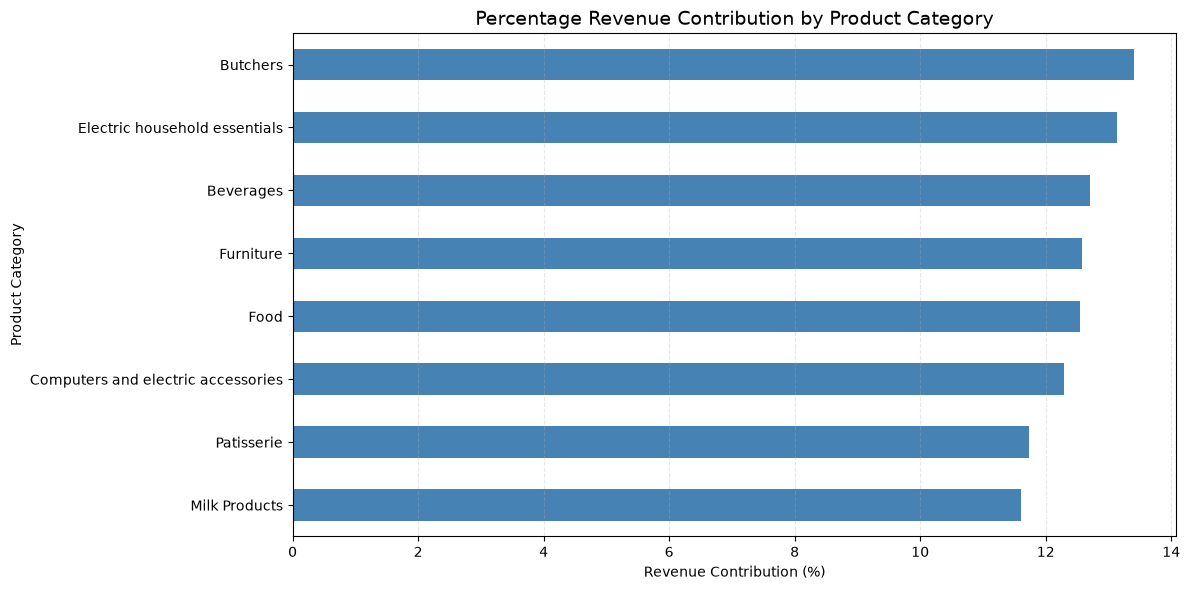

In [28]:

# Step 37: Visualize percentage revenue contribution

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

category_percentage.sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title(
    "Percentage Revenue Contribution by Product Category",
    fontsize=14
)

plt.xlabel("Revenue Contribution (%)")
plt.ylabel("Product Category")

plt.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


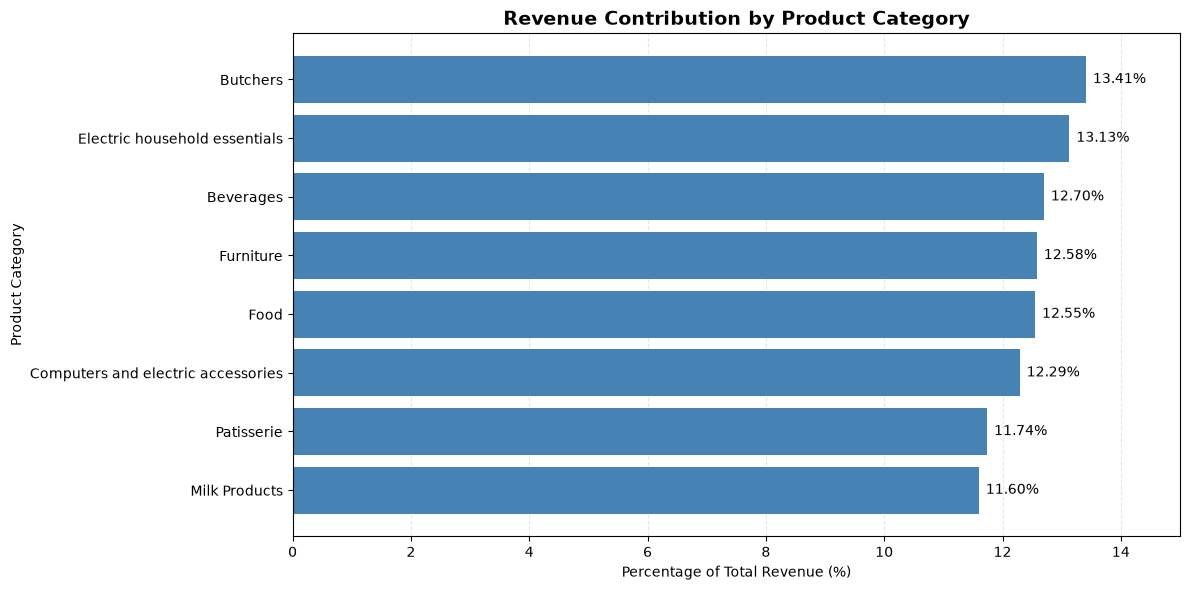

In [29]:

# Step 38: Improve the revenue contribution chart

import matplotlib.pyplot as plt

# Sort categories from lowest to highest
sorted_percentage = category_percentage.sort_values()

fig, ax = plt.subplots(figsize=(12, 6))

# Create horizontal bars
bars = ax.barh(
    sorted_percentage.index,
    sorted_percentage.values,
    color="steelblue"
)

# Add percentage labels
ax.bar_label(
    bars,
    labels=[f"{value:.2f}%" for value in sorted_percentage.values],
    padding=5
)

# Chart formatting
ax.set_title(
    "Revenue Contribution by Product Category",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Percentage of Total Revenue (%)")
ax.set_ylabel("Product Category")
ax.set_xlim(0, 15)

ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

# Save the chart in high resolution
plt.savefig(
    "revenue_contribution_by_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [30]:
import os

filename = "revenue_contribution_by_category.png"

print("File exists:", os.path.exists(filename))
print("Working directory:", os.getcwd())

File exists: True
Working directory: C:\Users\hp\OneDrive\Desktop\Ecommerce_Sales_Analysis


In [31]:

# Step 40: Calculate total revenue by year

# Ensure transaction dates are in datetime format
df_revenue["Transaction Date"] = pd.to_datetime(
    df_revenue["Transaction Date"]
)

# Extract the year from each transaction date
df_revenue["Transaction Year"] = (
    df_revenue["Transaction Date"].dt.year
)

# Calculate total revenue for each year
yearly_revenue = (
    df_revenue.groupby("Transaction Year")["Total Spent"]
    .sum()
    .sort_index()
)

# Display the results
print("Total Revenue by Year:")
print(yearly_revenue.round(2))


Total Revenue by Year:
Transaction Year
2022    510329.5
2023    491312.0
2024    524881.0
2025     25548.5
Name: Total Spent, dtype: float64


In [32]:

# Step 41: Check transaction date coverage by year

year_coverage = (
    df_revenue.groupby("Transaction Year")
    .agg(
        First_Transaction=("Transaction Date", "min"),
        Last_Transaction=("Transaction Date", "max"),
        Total_Transactions=("Transaction Date", "count"),
        Months_Recorded=("Transaction Date",
                         lambda x: x.dt.to_period("M").nunique())
    )
)

print("Transaction Date Coverage by Year:")
print(year_coverage)


Transaction Date Coverage by Year:
                 First_Transaction Last_Transaction  Total_Transactions  \
Transaction Year                                                          
2022                    2022-01-01       2022-12-31                3925   
2023                    2023-01-01       2023-12-31                3808   
2024                    2024-01-01       2024-12-31                4036   
2025                    2025-01-01       2025-01-18                 202   

                  Months_Recorded  
Transaction Year                   
2022                           12  
2023                           12  
2024                           12  
2025                            1  


In [33]:

# Step 42: Compare January 1–18 revenue across years

# Select transactions occurring between January 1 and January 18
january_comparison = df_revenue[
    (df_revenue["Transaction Date"].dt.month == 1) &
    (df_revenue["Transaction Date"].dt.day <= 18)
]

# Calculate revenue for the same period in each year
january_revenue = (
    january_comparison
    .groupby("Transaction Year")["Total Spent"]
    .sum()
    .sort_index()
)

print("Revenue Comparison: January 1–18")
print(january_revenue.round(2))


Revenue Comparison: January 1–18
Transaction Year
2022    28906.5
2023    29420.5
2024    26497.0
2025    25548.5
Name: Total Spent, dtype: float64


In [34]:

# Step 43: Calculate year-over-year revenue change

revenue_2024 = january_revenue.loc[2024]
revenue_2025 = january_revenue.loc[2025]

percentage_change = (
    (revenue_2025 - revenue_2024) / revenue_2024
) * 100

print(f"2024 Revenue: {revenue_2024:,.2f}")
print(f"2025 Revenue: {revenue_2025:,.2f}")
print(f"Revenue Percentage Change: {percentage_change:.2f}%")


2024 Revenue: 26,497.00
2025 Revenue: 25,548.50
Revenue Percentage Change: -3.58%


In [35]:

# Step 44: Compare transaction volume and average spending

january_performance = (
    january_comparison
    .groupby("Transaction Year")
    .agg(
        Total_Revenue=("Total Spent", "sum"),
        Transactions=("Transaction ID", "count"),
        Average_Transaction_Value=("Total Spent", "mean")
    )
    .round(2)
)

print("January 1–18 Sales Performance:")
print(january_performance)


January 1–18 Sales Performance:
                  Total_Revenue  Transactions  Average_Transaction_Value
Transaction Year                                                        
2022                    28906.5           210                     137.65
2023                    29420.5           218                     134.96
2024                    26497.0           207                     128.00
2025                    25548.5           202                     126.48


In [36]:

# Step 45: Compare category revenue for January 1–18

category_comparison = (
    january_comparison[
        january_comparison["Transaction Year"].isin([2024, 2025])
    ]
    .pivot_table(
        index="Category",
        columns="Transaction Year",
        values="Total Spent",
        aggfunc="sum",
        fill_value=0
    )
)

# Calculate the revenue difference
category_comparison["Revenue Change"] = (
    category_comparison[2025] - category_comparison[2024]
)

# Sort from largest decline to largest increase
category_comparison = category_comparison.sort_values(
    "Revenue Change"
)

print("Category Revenue Comparison: 2024 vs 2025")
print(category_comparison.round(2))


Category Revenue Comparison: 2024 vs 2025
Transaction Year                      2024    2025  Revenue Change
Category                                                          
Electric household essentials       4122.5  2984.5         -1138.0
Furniture                           3493.0  2686.0          -807.0
Beverages                           4056.0  3554.5          -501.5
Patisserie                          2094.0  1732.5          -361.5
Butchers                            4189.0  3849.5          -339.5
Milk Products                       1968.5  2086.0           117.5
Food                                3779.5  4267.5           488.0
Computers and electric accessories  2794.5  4388.0          1593.5


In [37]:

# Step 46: Calculate percentage revenue change by category

category_comparison["Percentage Change"] = (
    (category_comparison[2025] - category_comparison[2024])
    / category_comparison[2024]
) * 100

print("Category Revenue Growth and Decline (%):")
print(category_comparison.round(2))


Category Revenue Growth and Decline (%):
Transaction Year                      2024    2025  Revenue Change  \
Category                                                             
Electric household essentials       4122.5  2984.5         -1138.0   
Furniture                           3493.0  2686.0          -807.0   
Beverages                           4056.0  3554.5          -501.5   
Patisserie                          2094.0  1732.5          -361.5   
Butchers                            4189.0  3849.5          -339.5   
Milk Products                       1968.5  2086.0           117.5   
Food                                3779.5  4267.5           488.0   
Computers and electric accessories  2794.5  4388.0          1593.5   

Transaction Year                    Percentage Change  
Category                                               
Electric household essentials                  -27.60  
Furniture                                      -23.10  
Beverages                         

In [38]:

# Step 47: Investigate category transaction performance

category_performance = (
    january_comparison[
        january_comparison["Transaction Year"].isin([2024, 2025])
    ]
    .groupby(["Category", "Transaction Year"])
    .agg(
        Transactions=("Transaction ID", "count"),
        Average_Transaction_Value=("Total Spent", "mean")
    )
    .round(2)
)

print("Category Transaction Performance: 2024 vs 2025")
print(category_performance)


Category Transaction Performance: 2024 vs 2025
                                                     Transactions  \
Category                           Transaction Year                 
Beverages                          2024                        27   
                                   2025                        25   
Butchers                           2024                        29   
                                   2025                        25   
Computers and electric accessories 2024                        21   
                                   2025                        30   
Electric household essentials      2024                        32   
                                   2025                        25   
Food                               2024                        31   
                                   2025                        36   
Furniture                          2024                        28   
                                   2025                 

In [39]:

# Step 49: Investigate furniture transaction volume

# Filter furniture transactions
furniture_sales = january_comparison[
    january_comparison["Category"] == "Furniture"
]

# Compare furniture performance by year
furniture_performance = (
    furniture_sales
    .groupby("Transaction Year")
    .agg(
        Total_Revenue=("Total Spent", "sum"),
        Transactions=("Transaction ID", "count"),
        Average_Transaction_Value=("Total Spent", "mean")
    )
    .round(2)
)

# Display results
print("Furniture Sales Performance: January 1–18")
print(furniture_performance)


Furniture Sales Performance: January 1–18
                  Total_Revenue  Transactions  Average_Transaction_Value
Transaction Year                                                        
2022                     3751.0            29                     129.34
2023                     2352.0            20                     117.60
2024                     3493.0            28                     124.75
2025                     2686.0            20                     134.30


In [40]:

# Step 51: Analyze payment method performance

# Group revenue-ready transactions by payment method
payment_performance = (
    df_revenue
    .groupby("Payment Method")
    .agg(
        Total_Revenue=("Total Spent", "sum"),
        Transactions=("Total Spent", "count"),
        Average_Transaction_Value=("Total Spent", "mean")
    )
    .sort_values("Total_Revenue", ascending=False)
    .round(2)
)

# Display results
print("Sales Performance by Payment Method:")
print(payment_performance)

# Verify total revenue
print("\nTotal Revenue Across Payment Methods:")
print(payment_performance["Total_Revenue"].sum().round(2))


Sales Performance by Payment Method:
                Total_Revenue  Transactions  Average_Transaction_Value
Payment Method                                                        
Cash                 537710.0          4103                     131.05
Digital Wallet       507279.0          3941                     128.72
Credit Card          507082.0          3927                     129.13

Total Revenue Across Payment Methods:
1552071.0


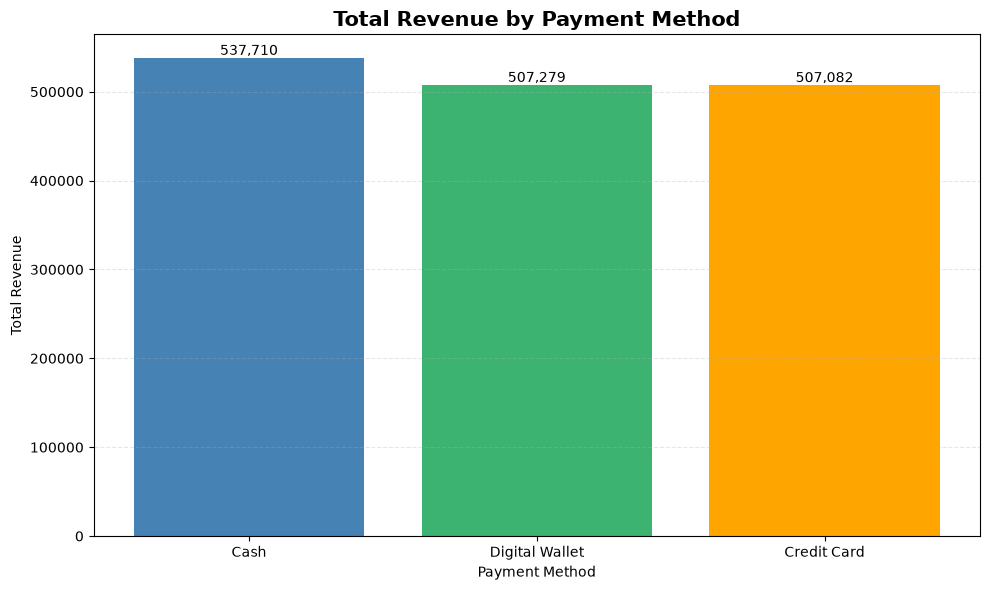

In [41]:

# Step 53: Visualize revenue by payment method

import matplotlib.pyplot as plt

# Extract revenue by payment method
payment_revenue = payment_performance["Total_Revenue"]

# Create bar chart
plt.figure(figsize=(10, 6))

bars = plt.bar(
    payment_revenue.index,
    payment_revenue.values,
    color=["steelblue", "mediumseagreen", "orange"]
)

# Add chart title and labels
plt.title(
    "Total Revenue by Payment Method",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Payment Method")
plt.ylabel("Total Revenue")

# Add revenue labels above bars
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:,.0f}",
        ha="center",
        va="bottom"
    )

# Improve layout
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()

# Save chart for portfolio
plt.savefig(
    "revenue_by_payment_method.png",
    dpi=300,
    bbox_inches="tight"
)

# Display chart
plt.show()


In [42]:

# Step 54: Calculate payment method revenue contribution

# Calculate each payment method's percentage contribution
payment_percentage = (
    payment_performance["Total_Revenue"]
    / payment_performance["Total_Revenue"].sum()
    * 100
).round(2)

# Display results
print("Revenue Contribution by Payment Method (%):")
print(payment_percentage)

# Verify percentages add up to approximately 100%
print("\nTotal Percentage:")
print(payment_percentage.sum().round(2))


Revenue Contribution by Payment Method (%):
Payment Method
Cash              34.64
Digital Wallet    32.68
Credit Card       32.67
Name: Total_Revenue, dtype: float64

Total Percentage:
99.99


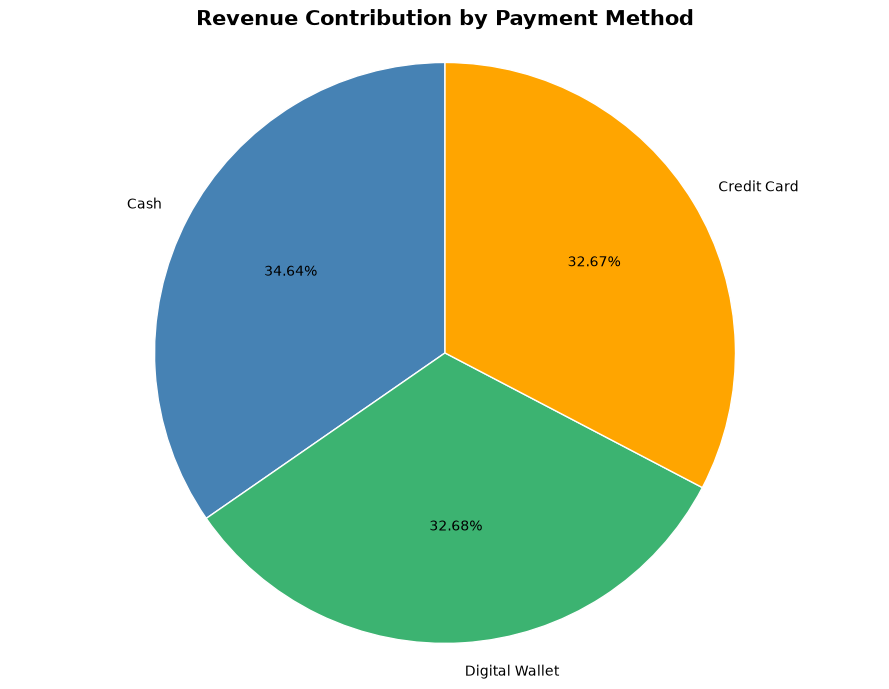

In [43]:

# Step 55: Visualize payment method revenue contribution

import matplotlib.pyplot as plt

# Use unrounded revenue values for accurate percentages
payment_revenue = payment_performance["Total_Revenue"]

# Create pie chart
plt.figure(figsize=(9, 7))

plt.pie(
    payment_revenue,
    labels=payment_revenue.index,
    autopct="%1.2f%%",
    startangle=90,
    colors=["steelblue", "mediumseagreen", "orange"],
    wedgeprops={"edgecolor": "white"}
)

# Add chart title
plt.title(
    "Revenue Contribution by Payment Method",
    fontsize=15,
    fontweight="bold"
)

plt.axis("equal")
plt.tight_layout()

# Save chart for portfolio
plt.savefig(
    "payment_method_revenue_share.png",
    dpi=300,
    bbox_inches="tight"
)

# Display chart
plt.show()


In [44]:

# Step 56: Inspect columns for customer analysis

print("Available Columns:")
print(df_revenue.columns.tolist())


Available Columns:
['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit', 'Quantity', 'Total Spent', 'Payment Method', 'Location', 'Transaction Date', 'Discount Applied', 'Transaction Year']


In [45]:

# Step 57: Analyze customer purchase frequency

# Count transactions for each customer
customer_transactions = (
    df_revenue.groupby("Customer ID")["Transaction ID"]
    .nunique()
    .sort_values(ascending=False)
)

# Calculate customer metrics
total_customers = len(customer_transactions)

one_time_customers = (customer_transactions == 1).sum()

repeat_customers = (customer_transactions > 1).sum()

# Display results
print("Customer Purchase Frequency Analysis")
print("Total Unique Customers:", total_customers)
print("One-Time Customers:", one_time_customers)
print("Repeat Customers:", repeat_customers)

print("\nTop 10 Customers by Transaction Count:")
print(customer_transactions.head(10))


Customer Purchase Frequency Analysis
Total Unique Customers: 25
One-Time Customers: 0
Repeat Customers: 25

Top 10 Customers by Transaction Count:
Customer ID
CUST_24    519
CUST_05    516
CUST_13    508
CUST_08    507
CUST_15    501
CUST_09    498
CUST_16    494
CUST_01    485
CUST_11    481
CUST_23    481
Name: Transaction ID, dtype: int64


In [46]:

# Step 58: Analyze customer spending and revenue contribution

# Calculate revenue and transaction count for each customer
customer_spending = (
    df_revenue.groupby("Customer ID")
    .agg(
        Total_Revenue=("Total Spent", "sum"),
        Transactions=("Transaction ID", "nunique")
    )
)

# Calculate average transaction value
customer_spending["Average_Transaction_Value"] = (
    customer_spending["Total_Revenue"] /
    customer_spending["Transactions"]
)

# Calculate each customer's contribution to total revenue
customer_spending["Revenue_Contribution_Percent"] = (
    customer_spending["Total_Revenue"] /
    customer_spending["Total_Revenue"].sum()
) * 100

# Sort customers by highest revenue
customer_spending = customer_spending.sort_values(
    by="Total_Revenue",
    ascending=False
)

# Display the top 10 customers
print("Top 10 Customers by Total Revenue:")
print(customer_spending.head(10).round(2))

# Verify revenue
print("\nTotal Customer Revenue:")
print(round(customer_spending["Total_Revenue"].sum(), 2))


Top 10 Customers by Total Revenue:
             Total_Revenue  Transactions  Average_Transaction_Value  \
Customer ID                                                           
CUST_24            68452.0           519                     131.89   
CUST_08            67351.5           507                     132.84   
CUST_05            66974.5           516                     129.80   
CUST_16            65570.5           494                     132.73   
CUST_13            65037.0           508                     128.03   
CUST_23            64507.0           481                     134.11   
CUST_10            63155.5           481                     131.30   
CUST_15            63117.5           501                     125.98   
CUST_21            62933.0           476                     132.21   
CUST_02            62046.5           467                     132.86   

             Revenue_Contribution_Percent  
Customer ID                                
CUST_24                 

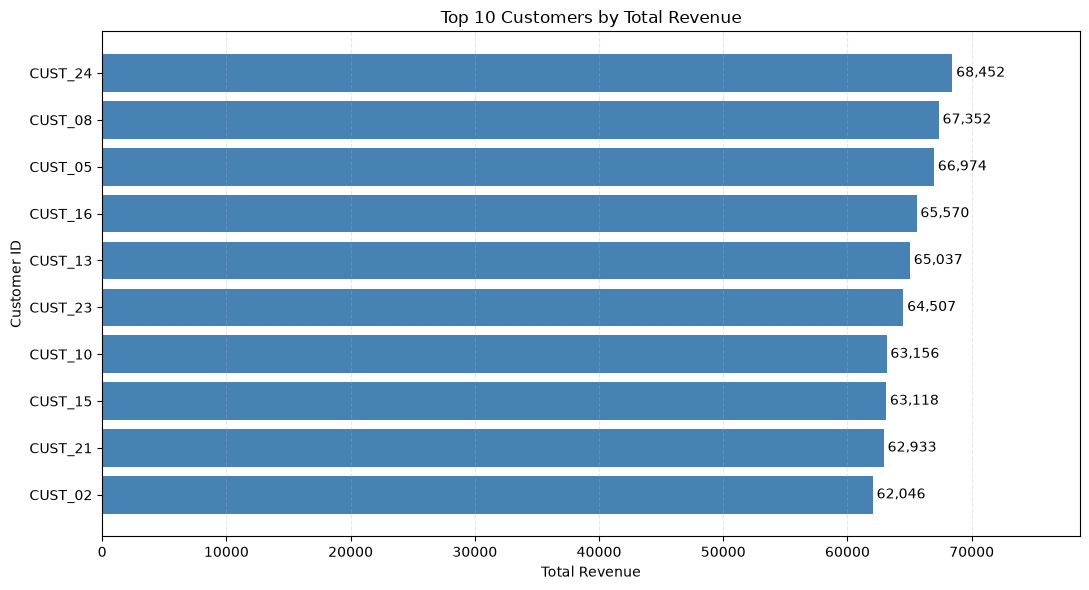

In [47]:

# Step 59: Visualize top 10 customers by revenue

import matplotlib.pyplot as plt

# Select the top 10 customers
top_customers = customer_spending.head(10)

# Create horizontal bar chart
plt.figure(figsize=(11, 6))

bars = plt.barh(
    top_customers.index,
    top_customers["Total_Revenue"],
    color="steelblue"
)

# Put the highest revenue customer at the top
plt.gca().invert_yaxis()

# Add revenue labels
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 300,
        bar.get_y() + bar.get_height() / 2,
        f"{width:,.0f}",
        va="center"
    )

plt.title("Top 10 Customers by Total Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Customer ID")
plt.xlim(0, top_customers["Total_Revenue"].max() * 1.15)
plt.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()

# Save chart for portfolio
plt.savefig(
    "top_10_customers_by_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [48]:

# Step 60: Calculate customer revenue concentration

# Calculate total customer revenue
total_customer_revenue = customer_spending["Total_Revenue"].sum()

# Calculate revenue generated by top 5 customers
top_5_revenue = customer_spending.head(5)["Total_Revenue"].sum()

# Calculate revenue generated by top 10 customers
top_10_revenue = customer_spending.head(10)["Total_Revenue"].sum()

# Convert revenue into percentages
top_5_percentage = (top_5_revenue / total_customer_revenue) * 100
top_10_percentage = (top_10_revenue / total_customer_revenue) * 100

# Display results
print(f"Top 5 Customer Revenue Contribution: {top_5_percentage:.2f}%")
print(f"Top 10 Customer Revenue Contribution: {top_10_percentage:.2f}%")


Top 5 Customer Revenue Contribution: 21.48%
Top 10 Customer Revenue Contribution: 41.82%


In [49]:

# Step 61: Calculate average customer spending

# Calculate average revenue per customer
average_customer_revenue = (
    customer_spending["Total_Revenue"].mean()
)

# Find highest and lowest customer revenue
highest_customer_revenue = (
    customer_spending["Total_Revenue"].max()
)

lowest_customer_revenue = (
    customer_spending["Total_Revenue"].min()
)

# Display results
print(f"Average Revenue Per Customer: {average_customer_revenue:,.2f}")
print(f"Highest Customer Revenue: {highest_customer_revenue:,.2f}")
print(f"Lowest Customer Revenue: {lowest_customer_revenue:,.2f}")


Average Revenue Per Customer: 62,082.84
Highest Customer Revenue: 68,452.00
Lowest Customer Revenue: 57,155.50


In [50]:

# Step 62: Analyze customer spending variability

# Calculate standard deviation
spending_std = customer_spending["Total_Revenue"].std()

# Calculate coefficient of variation
spending_cv = (
    spending_std / average_customer_revenue
) * 100

# Display results
print(f"Average Customer Revenue: {average_customer_revenue:,.2f}")
print(f"Standard Deviation: {spending_std:,.2f}")
print(f"Coefficient of Variation: {spending_cv:.2f}%")


Average Customer Revenue: 62,082.84
Standard Deviation: 2,933.82
Coefficient of Variation: 4.73%


In [51]:

# Step 63: Customer Segmentation by Revenue

# Create a copy to preserve the original analysis
customer_segments = customer_spending.copy()

# Divide customers into three revenue-based groups
customer_segments["Customer_Segment"] = pd.qcut(
    customer_segments["Total_Revenue"].rank(method="first"),
    q=3,
    labels=["Low Revenue", "Medium Revenue", "High Revenue"]
)

# Summarize customer segments
segment_summary = (
    customer_segments.groupby(
        "Customer_Segment", observed=True
    )
    .agg(
        Customers=("Total_Revenue", "count"),
        Total_Revenue=("Total_Revenue", "sum"),
        Average_Revenue=("Total_Revenue", "mean")
    )
)

# Calculate each segment's contribution to total revenue
segment_summary["Revenue_Percentage"] = (
    segment_summary["Total_Revenue"]
    / segment_summary["Total_Revenue"].sum()
    * 100
)

# Display results
print("Customer Revenue Segmentation:")
print(segment_summary.round(2))


Customer Revenue Segmentation:
                  Customers  Total_Revenue  Average_Revenue  \
Customer_Segment                                              
Low Revenue               9       534298.5         59366.50   
Medium Revenue            8       493607.0         61700.88   
High Revenue              8       524165.5         65520.69   

                  Revenue_Percentage  
Customer_Segment                      
Low Revenue                    34.42  
Medium Revenue                 31.80  
High Revenue                   33.77  


In [52]:

# Step 64: Analyze customer purchasing behavior over time

# Create a copy of the transaction data
customer_activity = df_revenue.copy()

# Ensure transaction dates are datetime
customer_activity["Transaction Date"] = pd.to_datetime(
    customer_activity["Transaction Date"]
)

# Create a monthly period column
customer_activity["Transaction Month"] = (
    customer_activity["Transaction Date"].dt.to_period("M")
)

# Calculate monthly customer activity
monthly_customer_activity = (
    customer_activity.groupby("Transaction Month")
    .agg(
        Active_Customers=("Customer ID", "nunique"),
        Transactions=("Transaction ID", "count"),
        Total_Revenue=("Total Spent", "sum")
    )
    .sort_index()
)

# Calculate transactions per active customer
monthly_customer_activity["Transactions_Per_Customer"] = (
    monthly_customer_activity["Transactions"]
    / monthly_customer_activity["Active_Customers"]
)

# Display results
print("Monthly Customer Purchasing Behavior:")
print(monthly_customer_activity.round(2).to_string())


Monthly Customer Purchasing Behavior:
                   Active_Customers  Transactions  Total_Revenue  Transactions_Per_Customer
Transaction Month                                                                          
2022-01                          25           368        52911.5                      14.72
2022-02                          25           313        43325.5                      12.52
2022-03                          25           339        40996.0                      13.56
2022-04                          25           334        40442.0                      13.36
2022-05                          25           315        40347.5                      12.60
2022-06                          25           321        42576.0                      12.84
2022-07                          25           349        44471.5                      13.96
2022-08                          25           331        41333.5                      13.24
2022-09                          25       

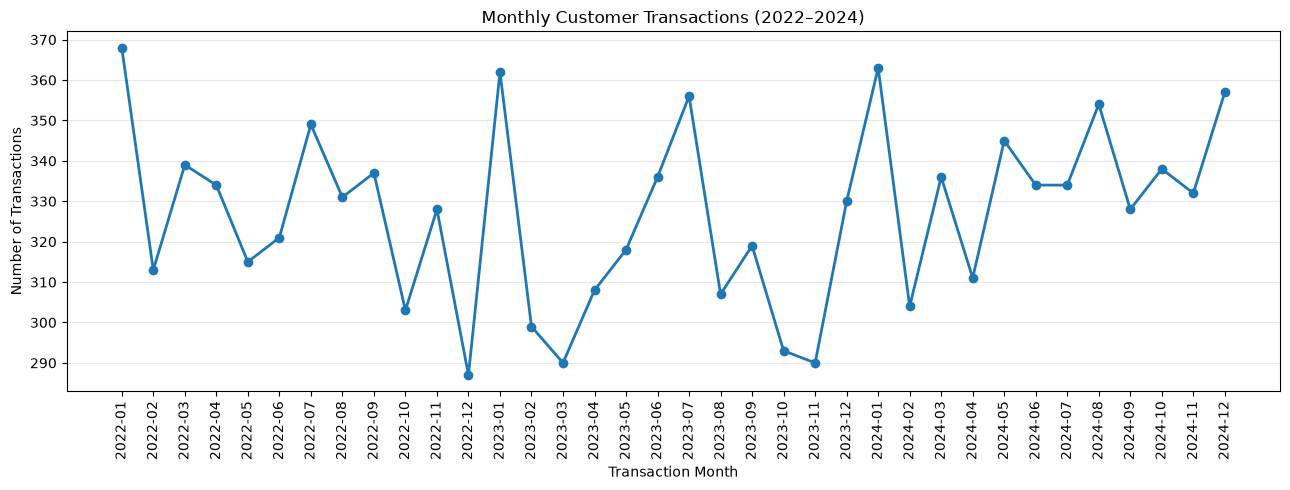

In [53]:

# Step 65: Visualize monthly customer purchasing behavior

import matplotlib.pyplot as plt

# Exclude incomplete January 2025
monthly_activity_full = monthly_customer_activity.loc[
    monthly_customer_activity.index < pd.Period("2025-01")
]

# Create the chart
plt.figure(figsize=(13, 5))

plt.plot(
    monthly_activity_full.index.astype(str),
    monthly_activity_full["Transactions"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Customer Transactions (2022–2024)")
plt.xlabel("Transaction Month")
plt.ylabel("Number of Transactions")

plt.xticks(rotation=90)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Save chart for GitHub portfolio
plt.savefig(
    "monthly_customer_transactions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## Customer Analysis: Findings and Business Recommendations

### Key Findings

The customer analysis examined purchasing frequency, revenue contribution, customer segmentation, and monthly transaction activity.

**1. Customer purchasing frequency**

The dataset contains 25 unique customer IDs, all associated with multiple transactions. All 25 IDs also appear in every recorded month. This suggests a fixed customer population in the dataset rather than necessarily demonstrating genuine customer retention.

**2. Customer revenue distribution**

- Average revenue per customer ID: 62,082.84
- Standard deviation: 2,933.82
- Coefficient of variation: 4.73%
- Top 5 customer revenue contribution: 21.48%
- Top 10 customer revenue contribution: 41.82%

The relatively low coefficient of variation indicates that aggregate customer revenue is distributed fairly evenly across the recorded customer IDs.

**3. Customer segmentation**

Customers were divided into low-, medium-, and high-revenue segments based on their relative spending rankings.

The low-revenue segment contributed 34.42% of total revenue, the medium-revenue segment contributed 31.80%, and the high-revenue segment contributed 33.77%.

The low-revenue segment contributed slightly more total revenue because it contained nine customers, compared with eight customers in each of the other segments.

**4. Monthly purchasing behavior**

Monthly transaction volumes fluctuated between 2022 and 2024, without a clear sustained upward or downward trend. January showed relatively high transaction activity across all three years.

### Business Recommendations

1. **Investigate customer identification:** Verify whether the 25 customer IDs represent individual customers or reused identifiers before calculating retention or loyalty metrics.

2. **Monitor transaction activity:** Track monthly transaction counts and revenue to identify unusual fluctuations and investigate potential seasonal patterns.

3. **Develop targeted customer strategies:** Use revenue segmentation as an initial exploratory tool, but validate customer identities and purchasing histories before implementing personalized campaigns.

4. **Monitor revenue concentration:** Track how much revenue comes from the highest-spending customer IDs to identify potential dependence on a small customer group.

### Limitations

The dataset contains only 25 unique customer IDs, each associated with unusually frequent purchases. This limits the reliability of conclusions about real-world customer loyalty, retention, and segmentation.

Additionally, January 2025 contains only 18 days of transactions and was excluded from the full-month visualization.

### Conclusion

Customer revenue is relatively evenly distributed across the recorded customer IDs, while monthly transaction activity fluctuates without a clear long-term trend. Further validation of customer identifiers would improve the reliability of customer-level business recommendations.

# Final Business Insights and Recommendations

## Executive Summary


This E-commerce Sales Analysis project examines transaction data from 2022 through January 18, 2025, using Python, pandas, and Matplotlib to evaluate revenue performance, product categories, payment methods, and customer purchasing behavior.

### Key Findings

**1. Overall Revenue Performance**

The dataset generated total recorded revenue of **1,552,071** across the analyzed transactions.

**2. Payment Method Performance**

Cash contributed the highest share of revenue at **34.64%**, followed by Digital Wallets (**32.68%**) and Credit Cards (**32.67%**). Revenue was relatively evenly distributed across the three payment methods.

**3. Product Category Performance**

Between January 1–18, 2024 and the corresponding period in 2025, Computers and Electric Accessories recorded the strongest revenue growth (**57.02%**), while Electric Household Essentials experienced the largest decline (**27.60%**).

**4. Customer Revenue Distribution**

The top five recorded customer IDs contributed **21.48%** of total revenue, while the top ten contributed **41.82%**. Customer revenue showed relatively low variability, with a coefficient of variation of **4.73%**.

**5. Customer Behavior and Data Limitations**

The dataset contains only **25 unique customer IDs**, each associated with unusually frequent transactions. Therefore, conclusions about customer loyalty and retention require additional validation.

January 2025 also contains only 18 days of transactions, making full-month comparisons inappropriate without adjusting for the incomplete period.

### Overall Business Insight

The analysis highlights opportunities to monitor declining product categories, strengthen growing categories, maintain support for multiple payment methods, and improve customer data quality before implementing personalized retention strategies.



## Final Business Recommendations

Based on the findings from the E-commerce Sales Analysis, the following recommendations are proposed:

### 1. Strengthen High-Growth Product Categories
Investigate the factors behind the 57.02% revenue increase in Computers and Electric Accessories during January 1–18, 2025, compared with the same period in 2024. Evaluate inventory availability, pricing, and promotional activity before expanding investment.

### 2. Investigate Declining Product Categories
Electric Household Essentials experienced a 27.60% revenue decline over the comparable January periods. Review product demand, pricing, stock availability, and competitor activity to identify potential causes.

### 3. Maintain Multiple Payment Options
Cash, Digital Wallets, and Credit Cards each contributed approximately one-third of total revenue. Continue supporting all three payment methods and monitor transaction costs, customer preferences, and payment reliability.

### 4. Improve Customer Data Quality
Verify whether the 25 customer IDs represent genuine individual customers. Reliable identifiers are necessary before implementing loyalty programs, calculating retention rates, or developing personalized marketing campaigns.

### 5. Monitor Revenue Concentration
The top ten recorded customer IDs contributed 41.82% of total revenue. Monitor this concentration over time and investigate whether revenue depends disproportionately on a limited number of customers.

### 6. Improve Sales Performance Monitoring
Develop a recurring dashboard tracking revenue, transaction volume, average transaction value, product category performance, and payment method contributions. Compare equivalent reporting periods to avoid misleading conclusions from incomplete months.

## Final Project Conclusion

This project demonstrates how Python-based exploratory data analysis can transform transaction records into actionable business insights.

The findings identify opportunities to investigate product category performance, maintain accessible payment options, monitor revenue concentration, and improve customer data quality.

However, the recommendations are exploratory rather than causal conclusions. Further investigation and additional validated customer data would strengthen business decision-making.
